In [1]:
import ROOT
import pandas as pd
import numpy as np
import os
import sys
import ipynbname
from pathlib import Path

project_root = str(ipynbname.path().parent.parent)
sys.path.append(project_root)
project_root=Path(project_root)

from processing import SiphraAcquisition, MetadataLoader
from analysis import fit_peak_expbg

# Constants
BITS12 = 2**12
BITS9 = 2**9 # 512 typical number of bins used

# Energy emission peaks in MeV
Cs137_MeV = 0.662
Na22_MeV = [0.511, 1.275, 1.786]
Co60_MeV = [1.173, 1.332, 2,505]
Am241_MeV = 0.0595
# Background emission
K40_MeV = 1.460
Tl208_MEV = 2.614

colors = [
    ROOT.kRed + 1,
    ROOT.kBlue + 1,
    ROOT.kGreen + 2,
    ROOT.kOrange + 7,
    ROOT.kMagenta + 1,
    ROOT.kCyan + 1,
    ROOT.kViolet + 2,
    ROOT.kPink + 7,
    ROOT.kTeal + 3,
    ROOT.kAzure + 2,
    ROOT.kSpring + 5,
    ROOT.kRed + 2,
    ROOT.kBlue + 2,
    ROOT.kGreen + 3,
]
siphras = ['A', 'B']

In [2]:
files = sorted((project_root/'data/DataForJohanna_260605').glob('*_DoubleSiphra_*.csv'))
acqs = [SiphraAcquisition(file) for file in files]
print(acqs)
print(len(acqs))
#print(acqs)
#Abackground = acqs[12]
#Bbackground = acqs[25]
backgrounds = [acqs[15], acqs[31]]
#calibrations = [acqs[0], acqs[13]]
Aacqs = acqs[1:15]
Bacqs = acqs[17:31]
acqs = [Aacqs, Bacqs]
print(backgrounds)
#print(calibrations)
#print(acqs)
print(Aacqs)
print(Bacqs)

[SIPHRAAcquisition(File: 'A04_Background_DoubleSiphra_DisableCh15SiphraB'), SIPHRAAcquisition(File: 'A05_Cs137At1cmFromSiphraB_DoubleSiphra_DisableCh15SiphraB'), SIPHRAAcquisition(File: 'A06_Cs137At2cmFromSiphraB_DoubleSiphra_DisableCh15SiphraB'), SIPHRAAcquisition(File: 'A07_Cs137At3cmFromSiphraB_DoubleSiphra_DisableCh15SiphraB'), SIPHRAAcquisition(File: 'A08_Cs137At4cmFromSiphraB_DoubleSiphra_DisableCh15SiphraB'), SIPHRAAcquisition(File: 'A09_Cs137At5cmFromSiphraB_DoubleSiphra_DisableCh15SiphraB'), SIPHRAAcquisition(File: 'A10_Cs137At6cmFromSiphraB_DoubleSiphra_DisableCh15SiphraB'), SIPHRAAcquisition(File: 'A11_Cs137At7cmFromSiphraB_DoubleSiphra_DisableCh15SiphraB'), SIPHRAAcquisition(File: 'A12_Cs137At8cmFromSiphraB_DoubleSiphra_DisableCh15SiphraB'), SIPHRAAcquisition(File: 'A13_Cs137At9cmFromSiphraB_DoubleSiphra_DisableCh15SiphraB'), SIPHRAAcquisition(File: 'A14_Cs137At10cmFromSiphraB_DoubleSiphra_DisableCh15SiphraB'), SIPHRAAcquisition(File: 'A15_Cs137At11cmFromSiphraB_DoubleSiphr

In [3]:
# Create histograms for background and each distance for both siphras. Create background subtracted histograms. 
hists = {}
distances_cm = list(range(1, 15))
print(distances_cm)
for i in range(len(siphras)):
    siphra = siphras[i]
    bg = backgrounds[i]

    #Background
    hist_bg = ROOT.TH1F(f"{siphra}_Background", "", BITS12, 0 , BITS12)
    hist_bg.Fill(bg['s']/len(bg.active_chs))
    hist_bg.GetXaxis().SetTitle("ADC channel number")
    hist_bg.GetYaxis().SetTitle(r"Normalized counts")
    hists[f"{siphra}_Background"] = hist_bg
    
    for sgnl, distance in zip(acqs[i], distances_cm):

        # Distance to A = 15 - distance to B
        if siphra == 'A':
            distance = 15-distance
        print(distance)
            
        filepath = sgnl.filepath.stem

        # Signal
        hist_sgnl = ROOT.TH1F(f"{siphra}_{distance}cm_signal", "", BITS12, 0, BITS12)
        hist_sgnl.Fill(sgnl['s']/len(sgnl.active_chs))      
        hist_sgnl.Scale(bg.exposure/sgnl.exposure)
        
        # Clean spectrum
        hist_clean = hist_sgnl.Clone(f"{siphra}_{distance}cm_clean")
        hist_clean.Add(hist_bg, -1)
        
        for hist in [hist_sgnl, hist_clean]:
            hist.GetXaxis().SetTitle("ADC channel number")
            hist.GetYaxis().SetTitle(r"Normalized counts")
            
        hists[f"{siphra}_{distance}cm_signal"] = hist_sgnl      
        hists[f"{siphra}_{distance}cm_clean"] = hist_clean
        
        del hist_sgnl
        del hist_clean
    del hist_bg

[1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14]
14
13
12
11
10
9
8
7
6
5
4
3
2
1
1
2
3
4
5
6
7
8
9
10
11
12
13
14


In [4]:
#Draw one histogram for each distance + siphra combination

if ROOT.gROOT.FindObject('cv1'):
    ROOT.gROOT.FindObject('cv1').Close()

Yinit = 0.82 # For stat boxes

cv1 = ROOT.TCanvas('cv1', 'cv1', 4800, 2400)
cv1.Divide(5, 6)

#cv1 = ROOT.TCanvas('cv1', 'cv1', 4800, 2400)
#cv1.Divide(5, 5)

ROOT.gStyle.SetOptStat(11)
ROOT.gStyle.SetStatFontSize(0.03)
ROOT.gStyle.SetStatW(0.16)

lgds = [ROOT.TLegend(0.48, 0.61, 0.75, 0.83) for _ in range(28)]

for i, siphra in enumerate(siphras):  
    for idx, distance in enumerate(distances_cm):
        lg = lgds[10*i + idx]
        cv1.cd(10*i+idx+1)
        cv1.cd(10*i+idx+1).SetLogy()
        
        bg = hists[f"{siphra}_Background"] 
        sgnl = hists[f"{siphra}_{distance}cm_signal"]         
        clean = hists[f"{siphra}_{distance}cm_clean"] 
        
        lg.AddEntry(sgnl, r"^{137}Cs signal")
        lg.AddEntry(bg, "Background")
        lg.AddEntry(clean, r"^{137}Cs, Background subtracted")
        
        sgnl.SetLineColor(colors[0])
        bg.SetLineColor(colors[1])
        clean.SetLineColor(colors[2])
        #sgnl.SetTitle(str(distance))
        #clean.SetTitle(f"SIPHRA {siphra} distance: {distance} cm")
        print(distance)
        sgnl.SetTitle(f"SIPHRA {siphra} distance: {distance} cm")

        # Drw histograms
        sgnl.Draw("hist")
        bg.Draw("sames hist")
        clean.Draw("sames hist")
        
        ROOT.gPad.Update()
        lg.Draw()
        cv1.Draw()
    


1
2
3
4
5
6
7
8
9
10
11
12
13
14
1
2
3
4
5
6
7
8
9
10
11
12
13
14


In [7]:
#Plot all the subtracted histogram spectra in one plot.

if ROOT.gROOT.FindObject('cv2'):
    ROOT.gROOT.FindObject('cv2').Close()

Yinit = 0.82 # For stat boxes

cv2 = ROOT.TCanvas('cv2', 'cv2', 2400, 1200)
cv2.Divide(2,1)

ROOT.gStyle.SetOptStat(11)
ROOT.gStyle.SetStatFontSize(0.03)
ROOT.gStyle.SetStatW(0.16)

lgds = [ROOT.TLegend(0.48, 0.61, 0.75, 0.83) for _ in range(2)]

for i, (siphra, lg) in enumerate(zip(siphras, lgds)):
    cv2.cd(i+1)
    cv2.cd(i+1).SetLogy()
    

    for idx, (distance) in enumerate(distances_cm):   
        
        clean = hists[f"{siphra}_{distance}cm_clean"] 
        lg.AddEntry(clean, f"Bg subtracted {distance} cm SIPHRA {siphra}")
        clean.SetLineColor(colors[idx])
        if idx ==0:
            clean.Draw("hist")
        else:
            clean.Draw("sames hist")
        ROOT.gPad.Update()
        
    lg.Draw()   
    cv2.Draw()

428.21398246915584
433.2447745524891
437.6046100119759
439.8037042133161
442.0186741912393
442.8958405363021
443.2222540220482
444.03828698061557
445.6462295813844
447.1858744138295
447.8526841651672
447.1457131735435
445.55223963828587
443.91235437545254
385.28392469312854
387.8342053255663
389.29548908583166
390.8728092053134
393.3747952605894
394.38263503519227
394.8046646480441
394.28835723342434
392.6278055776004
391.1140982129465
390.0273408713466
388.621069348407
387.3996603230356
387.1761177752819
[[np.float64(0.9687571215319145), np.float64(0.9801383838381413), np.float64(0.990001727453712), np.float64(0.9949767825796181), np.float64(0.9999877537948026), np.float64(1.0019721848931238), np.float64(1.0027106366995249), np.float64(1.004556764505671), np.float64(1.0081944454532368), np.float64(1.0116776149832474), np.float64(1.0131861521206629), np.float64(1.0115867574000543), np.float64(1.0079818101109623), np.float64(1.0042718646353275)], [np.float64(0.9866239894769739), np.floa

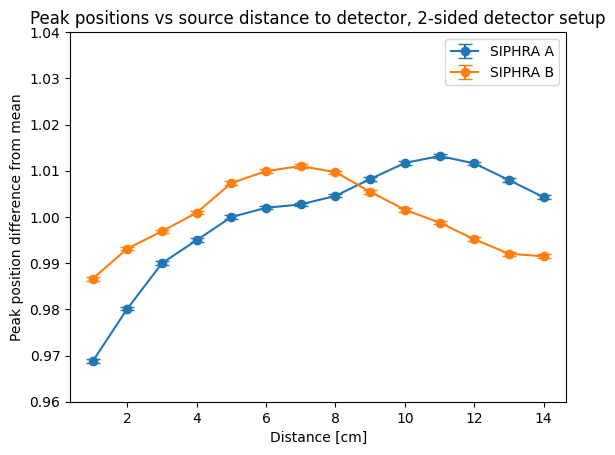

****************************************
Minimizer is Minuit2 / Migrad
Chi2                      =      413.985
NDf                       =          187
Edm                       =  7.27137e-06
NCalls                    =           66
Constant                  =      2168.09   +/-   6.43023     
Mean                      =      428.214   +/-   0.0938896   
Sigma                     =      36.3571   +/-   0.0787529    	 (limited)
****************************************
Minimizer is Minuit2 / Migrad
Chi2                      =      720.701
NDf                       =          187
Edm                       =  1.80958e-07
NCalls                    =           65
Constant                  =      2392.19   +/-   6.72831     
Mean                      =      433.245   +/-   0.0878504   
Sigma                     =      36.2978   +/-   0.0728588    	 (limited)
****************************************
Minimizer is Minuit2 / Migrad
Chi2                      =      914.959
NDf                   

In [6]:
#Plot the mean ADC value of the photopeak for each SIPHRA and distance. Include error bars.
#TODO: show as a percentage deviation from total mean? Like in Mozsis plot?

import matplotlib.pyplot as plt

means_list = []
mean_avg_list = []
error_list = []
diff_avg_list = []
for i, siphra in enumerate(siphras):
    means = []
    errors = []
    for j, distance in enumerate(distances_cm):
        hist = hists[f"{siphra}_{distance}cm_clean"] 
        gaus_fit = ROOT.TF1("gaus_fit", "gaus", 350, 540)
        hist.Fit(gaus_fit, "R+S")
        
        mean = gaus_fit.GetParameter(1)
        error = gaus_fit.GetParError(1)
        print(mean)
        means.append(mean)
        errors.append(error)
    means_list.append(means)
    mean_avg = np.mean(means)
    diff_avg = [x / mean_avg for x in means]
    diff_avg_errors = [e / mean_avg for e in errors]
    #mean_avg_list.append(mean_avg)
    error_list.append(errors)
    diff_avg_list.append(diff_avg)

print(diff_avg_list)




for i, (means, errors, siphra) in enumerate(zip(diff_avg_list, error_list, siphras)):
    plt.errorbar(
        distances_cm,
        means,
        yerr=diff_avg_errors,
        fmt='o-',        # 'o' means scatter points
        capsize=5,      # little caps on error bars
        label = f"SIPHRA {siphra}"
        #ecolor='black'
    )


plt.legend()
plt.xlabel("Distance [cm]")
plt.ylabel("Peak position difference from mean")
plt.ylim(0.96, 1.04)
plt.title("Peak positions vs source distance to detector, 2-sided detector setup")

plt.show()
        
        